# 0.4.2 tutorial — Jordan spectral primitives: `trace`, `determinant`, `unit`

Every Jordan-algebra space now exposes three spectral primitives derived from its
`spectrum`:

* **`trace(x)`** = sum of the Jordan eigenvalues `Σ λ_i`
* **`determinant(x)`** = product of the eigenvalues `Π λ_i`
* **`unit()`** = the algebra identity `e` (the all-ones-spectrum element)

They work uniformly across **elementwise**, **Hermitian**, **tree**, and **stacked**
spaces. This notebook shows each family, the trace inner-product identity, how the
**tree / stacked direct sums** compose leafwise, and a **timing comparison** showing
why the Hermitian `trace` is far cheaper than `determinant`.


In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import spacecore as sc
from tests._helpers import to_numpy  # tiny backend->numpy helper

ctx = sc.Context(sc.NumpyOps(), dtype=np.float64, check_level='none')
rng = np.random.default_rng(0)
print('spacecore', getattr(sc, '__version__', '?'))


spacecore 0.4.1


## 1. Elementwise Jordan algebra

An `ElementwiseJordanSpace` is coordinates under the pointwise product `x ∘ y = x * y`.
Its spectrum *is* the coordinate vector, so `trace` = sum of coordinates, `determinant`
= product, and the identity is the all-ones vector.

In [2]:
E = sc.ElementwiseJordanSpace((4,), ctx)
x = ctx.asarray([2.0, -1.0, 3.0, 0.5])
print('spectrum   :', to_numpy(E.spectrum(x)))
print('trace      :', float(to_numpy(E.trace(x))), ' (== sum  =', x.sum(), ')')
print('determinant:', float(to_numpy(E.determinant(x))), ' (== prod =', np.prod(to_numpy(x)), ')')
print('unit       :', to_numpy(E.unit()))
print('e o x == x  :', np.allclose(to_numpy(E.jordan(E.unit(), x)), to_numpy(x)))


spectrum   : [ 2.  -1.   3.   0.5]
trace      : 4.5  (== sum  = 4.5 )
determinant: -3.0  (== prod = -3.0 )
unit       : [1. 1. 1. 1.]
e o x == x  : True


## 2. Hermitian matrix algebra

A `HermitianSpace` is `n x n` Hermitian matrices under `x ∘ y = (xy + yx)/2`. The
Jordan spectrum is the eigenvalue spectrum, so `trace` is the matrix trace, `determinant`
the matrix determinant, and the identity is `Iₙ`. Note `trace` is computed from the
**diagonal** (no eigendecomposition) — that matters for section 6.

In [3]:
H = sc.HermitianSpace(3, ctx=ctx)
m = np.array([[2.0, 0.4, 0.0], [0.4, 1.0, 0.1], [0.0, 0.1, 3.0]])
X = ctx.asarray(m)
print('eigenvalues :', to_numpy(H.spectrum(X)))
print('trace       :', float(to_numpy(H.trace(X))), ' (== np.trace =', np.trace(m), ')')
print('determinant :', float(to_numpy(H.determinant(X))), ' (== np.linalg.det =', np.linalg.det(m), ')')
print('unit        :\n', to_numpy(H.unit()))


eigenvalues : [0.85553368 2.13905002 3.0054163 ]
trace       : 6.0  (== np.trace = 6.0 )
determinant : 5.5  (== np.linalg.det = 5.5 )
unit        :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## 3. The trace inner-product identity (Euclidean Jordan algebras)

On a Euclidean Jordan algebra, `trace` is a *linear* functional whose Riesz representative
is the unit: `trace(x) = ⟨e, x⟩`. This is the identity that makes `TraceFunctional` (a
later 0.4.2 item) have a constant gradient `e = unit()`.

In [4]:
for name, space, elt in [('elementwise', E, x), ('hermitian', H, X)]:
    lhs = float(np.real(to_numpy(space.trace(elt))))
    rhs = float(np.real(to_numpy(space.inner(space.unit(), elt))))
    print(f'{name:12s}: trace = {lhs:+.6f}   <unit, x> = {rhs:+.6f}   match = {np.isclose(lhs, rhs)}')


elementwise : trace = +4.500000   <unit, x> = +4.500000   match = True
hermitian   : trace = +6.000000   <unit, x> = +6.000000   match = True


## 4. Batched inputs keep the leading batch axis

`trace`/`determinant` reduce only the *intrinsic* axes, so a batch of matrices maps to a
batch of scalars.

In [5]:
B = rng.standard_normal((5, 3, 3))
B = 0.5 * (B + np.swapaxes(B, -1, -2))  # 5 Hermitian matrices
tr = H.trace(ctx.asarray(B))
print('input shape :', B.shape, '-> trace shape:', to_numpy(tr).shape)
print('per-matrix trace matches np.trace:',
      np.allclose(to_numpy(tr), [np.trace(b) for b in B]))


input shape : (5, 3, 3) -> trace shape: (5,)
per-matrix trace matches np.trace: True


## 5. Trees — direct sums that compose leafwise

A tree of Jordan leaves is a **direct sum** `⊕_i A_i` of the leaf algebras. Its spectrum is
the *concatenation* of the leaf spectra, so:

* **`trace` is additive**: `trace(⊕ xᵢ) = Σ trace(xᵢ)`
* **`determinant` is multiplicative**: `det(⊕ xᵢ) = Π det(xᵢ)`
* **`unit`** is the tree of the leaf units

The leaves can be **heterogeneous** — here a `2x2` Hermitian leaf *and* a length-3
elementwise leaf live in the same tree.

In [6]:
H2 = sc.HermitianSpace(2, ctx=ctx)
E3 = sc.ElementwiseJordanSpace((3,), ctx)
T = sc.TreeSpace.from_leaf_spaces((H2, E3), ctx)
print('tree is a Jordan algebra:', isinstance(T, sc.JordanAlgebraSpace),
      '| Euclidean:', isinstance(T, sc.EuclideanJordanAlgebraSpace))

mat = np.array([[2.0, 0.3], [0.3, 1.0]])   # Hermitian leaf
vec = np.array([1.0, -2.0, 3.0])           # elementwise leaf
xt = T.element((ctx.asarray(mat), ctx.asarray(vec)))

print('\ntrace(tree)       =', float(to_numpy(T.trace(xt))))
print('  additive check  = trace(H) + sum(E) =',
      np.trace(mat), '+', vec.sum(), '=', np.trace(mat) + vec.sum())
print('\ndeterminant(tree) =', float(to_numpy(T.determinant(xt))))
print('  mult. check     = det(H) * prod(E)  =',
      round(np.linalg.det(mat), 6), '*', vec.prod(), '=', round(np.linalg.det(mat) * vec.prod(), 6))

uh, ue = T.flatten_tree(T.unit())
print('\nunit(tree) leaves:')
print('  Hermitian leaf (I_2):\n', to_numpy(uh))
print('  elementwise leaf (ones):', to_numpy(ue))
print('  e o x == x on the tree :', np.allclose(to_numpy(T.flatten(T.jordan(T.unit(), xt))),
                                                 to_numpy(T.flatten(xt))))


tree is a Jordan algebra: True | Euclidean: True

trace(tree)       = 5.0
  additive check  = trace(H) + sum(E) = 3.0 + 2.0 = 5.0

determinant(tree) = -11.459999999999999
  mult. check     = det(H) * prod(E)  = 1.91 * -6.0 = -11.46

unit(tree) leaves:
  Hermitian leaf (I_2):
 [[1. 0.]
 [0. 1.]]
  elementwise leaf (ones): [1. 1. 1.]
  e o x == x on the tree : True


## 6. Stacked spaces — direct sum of identical copies

A `StackedSpace` stacks `count` copies of one base algebra. Same direct-sum rules: `trace`
sums over copies, `determinant` multiplies, and `unit` is the base identity replicated.

In [7]:
base = sc.HermitianSpace(2, ctx=ctx)
S = sc.StackedSpace(base, 3, ctx)
copies = [np.array([[1.0, 0.0], [0.0, 2.0]]),
          np.array([[3.0, 0.0], [0.0, 1.0]]),
          np.array([[2.0, 0.0], [0.0, 2.0]])]
xs = ctx.asarray(np.stack(copies))
print('trace(stack)       =', float(to_numpy(S.trace(xs))),
      '= sum of copy traces =', sum(np.trace(c) for c in copies))
print('determinant(stack) =', float(to_numpy(S.determinant(xs))),
      '= product of copy dets =', float(np.prod([np.linalg.det(c) for c in copies])))
print('unit(stack) shape  =', to_numpy(S.unit()).shape, '= I_2 replicated across 3 copies')


trace(stack)       = 11.0 = sum of copy traces = 11.0
determinant(stack) = 24.0 = product of copy dets = 24.000000000000004
unit(stack) shape  = (3, 2, 2) = I_2 replicated across 3 copies


## 7. Timing — `trace` avoids the eigendecomposition

For a Hermitian matrix, `trace` = sum of the diagonal (`O(n²)`), while `determinant` (and a
naive `sum(eigvalsh(x))` trace) needs a full eigendecomposition (`O(n³)`). The gap widens
fast with `n`.

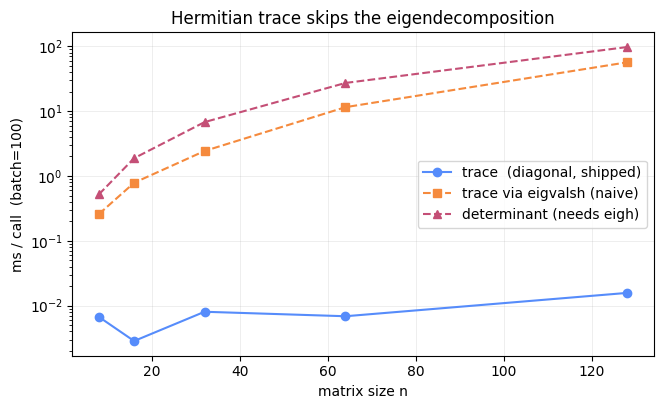

speedup of shipped trace vs the eigvalsh-based trace:
  n=   8:    0.007 ms  vs    0.258 ms   ->      39x
  n=  16:    0.003 ms  vs    0.786 ms   ->     276x
  n=  32:    0.008 ms  vs    2.430 ms   ->     302x
  n=  64:    0.007 ms  vs   11.524 ms   ->    1679x
  n= 128:    0.016 ms  vs   56.751 ms   ->    3608x


In [8]:
def bench(fn, arr, reps=10):
    fn(arr)  # warm up
    t = time.perf_counter()
    for _ in range(reps):
        fn(arr)
    return (time.perf_counter() - t) / reps * 1000.0  # ms

sizes = [8, 16, 32, 64, 128]
batch = 100
trace_ms, det_ms, naive_ms = [], [], []
for n in sizes:
    Hn = sc.HermitianSpace(n, ctx=ctx)
    A = rng.standard_normal((batch, n, n))
    A = ctx.asarray(0.5 * (A + np.swapaxes(A, -1, -2)))
    naive = lambda a: Hn.ops.sum(Hn.ops.eigvalsh(a), axis=-1)  # trace via eigenvalues
    trace_ms.append(bench(Hn.trace, A))
    det_ms.append(bench(Hn.determinant, A))
    naive_ms.append(bench(naive, A))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sizes, trace_ms, 'o-', label='trace  (diagonal, shipped)')
ax.plot(sizes, naive_ms, 's--', label='trace via eigvalsh (naive)')
ax.plot(sizes, det_ms, '^--', label='determinant (needs eigh)')
ax.set_yscale('log'); ax.set_xlabel('matrix size n'); ax.set_ylabel('ms / call  (batch=100)')
ax.set_title('Hermitian trace skips the eigendecomposition'); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

print('speedup of shipped trace vs the eigvalsh-based trace:')
for n, tr, na in zip(sizes, trace_ms, naive_ms):
    print(f'  n={n:4d}:  {tr:7.3f} ms  vs  {na:7.3f} ms   ->  {na/tr:6.0f}x')


## 8. Trees scale with the leaves

A tree trace is the sum of the per-leaf traces, so its cost grows with the number of
leaves — each leaf paying only its own (cheap, diagonal) Hermitian trace.

In [9]:
for k in [2, 8, 32]:
    leaves = tuple(sc.HermitianSpace(16, ctx=ctx) for _ in range(k))
    Tk = sc.TreeSpace.from_leaf_spaces(leaves, ctx)
    mats = tuple(ctx.asarray(0.5 * (mm + mm.T))
                 for mm in (rng.standard_normal((16, 16)) for _ in range(k)))
    xk = Tk.element(mats)
    ms = bench(Tk.trace, xk, reps=50)
    print(f'{k:3d} Hermitian(16) leaves:  trace {ms:.3f} ms')


  2 Hermitian(16) leaves:  trace 0.011 ms
  8 Hermitian(16) leaves:  trace 0.015 ms
 32 Hermitian(16) leaves:  trace 0.048 ms


## Summary

* `trace` / `determinant` / `unit` are available on every Jordan space, derived from the
  `spectrum`, and preserve leading batch axes.
* **Trees and stacked spaces are direct sums**: `trace` adds and `determinant` multiplies
  across leaves/copies, and `unit` is assembled from the leaf/copy units — with **no
  per-family special-casing** (the leafwise mixins inherit into every composite).
* Hermitian `trace` reads the diagonal, so it is orders of magnitude cheaper than
  `determinant`, which needs an eigendecomposition.


In [13]:
tree = {
    'A': sc.HermitianSpace(16, ctx=ctx),
    'B': sc.HermitianSpace(17, ctx=ctx)
}
space = sc.TreeSpace.from_template(tree, leaf_spaces=(sc.HermitianSpace(16, ctx=ctx), sc.HermitianSpace(17, ctx=ctx)))

In [22]:
space.from_spectrum(space.spectral_decompose(space.unit()))

{'A': array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 

In [20]:
sc.HermitianSpace(16, ctx=ctx).from_spectrum()

AttributeError: '_TreeEuclideanJordanStarSpace' object has no attribute 'leaf'